# مرحله Modeling نهایی — پروژه Online Retail

این نوت‌بوک بر اساس دو خروجی واقعی مرحله Data Preparation ساخته شده است:
- `customer_analysis.csv`: یک ردیف برای هر مشتری، شامل RFM، ویژگی‌های اقتصادی و ستون‌های استانداردشده `Seg_`.
- `product_basket.csv.gz`: ماتریس دودویی فاکتور × محصول برای Association Rule Mining.

**اهداف:** Customer Segmentation، Customer Economic Value، Marketing Opportunity، Association Rule Mining و انتخاب ۵۰۰ مشتری هدف. این پروژه پیش‌بینی Churn یا طبقه‌بندی نظارت‌شده نیست؛ بنابراین Accuracy طبقه‌بندی گزارش نمی‌شود.

**روش اجرا:** مسیر ورودی به‌صورت خودکار در پوشه جاری و والدهای آن جست‌وجو می‌شود. خروجی‌ها در `modeling_outputs` کنار پوشه داده‌ها ذخیره می‌شوند.

**دامنه ادعا:** این پیاده‌سازی فقط زوج‌های جهت‌دار از محصولات پرتکرار (حداکثر 150 قلم) را به‌صورت دقیق بررسی می‌کند؛ خروجی آن معادل اجرای کامل Apriori یا FP-Growth و استخراج itemsetهای چندمحصولی نیست. Lift بالا نیز هم‌خریدی را نشان می‌دهد، نه رابطه علّی.

**افزوده‌های نسخه ارائه:** آزمون پایداری با زیرنمونه‌گیری، تحلیل اندازه اثر و آزمون تفاوت خوشه‌ها، اعتبارسنجی تجاری Top-500 در برابر سایر مشتریان، نمودارهای مدیریتی و خروجی‌های CSV/JSON تکمیلی. آزمون‌های آماری صرفاً تفاوت توصیفی/آماری را می‌سنجند و جایگزین آزمایش کمپین یا گروه کنترل نیستند.

## 1. کتابخانه‌ها و تنظیمات

نیازمندی‌ها: `pandas`, `numpy`, `scikit-learn`, `scipy`, `matplotlib`, `seaborn`. نیازی به نصب `mlxtend` نیست؛ قوانین دوآیتمی با محاسبه دقیق هم‌رخدادی استخراج می‌شوند.

In [1]:
from pathlib import Path
import os, json, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.stats import spearmanr, mannwhitneyu

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
SIL_SAMPLE_SIZE = 2500
MIN_ITEM_SUPPORT = 0.005
MIN_CONFIDENCE = 0.30
MIN_LIFT = 1.10
MAX_ARM_ITEMS = 150

In [2]:
def locate_project_file(filename, start=None, max_parent_levels=5):
    start = Path(start or Path.cwd()).resolve()
    roots = [start] + list(start.parents[:max_parent_levels])
    matches = []
    seen = set()
    for root in roots:
        if not root.exists():
            continue
        for p in root.rglob(filename):
            if any(part in {'.git', '.ipynb_checkpoints', '__pycache__'} for part in p.parts):
                continue
            rp = p.resolve()
            if rp not in seen:
                seen.add(rp)
                matches.append(rp)
        if matches:
            break
    if not matches:
        raise FileNotFoundError(
            f"{filename} پیدا نشد. پوشه فعلی: {start}. "
            "فایل را داخل prepared_data یا یکی از زیرپوشه‌های پروژه قرار دهید."
        )
    # prepared_data اولویت دارد
    matches.sort(key=lambda p: (0 if p.parent.name.lower() == 'prepared_data' else 1,
                                len(p.parts), str(p)))
    best = (0 if matches[0].parent.name.lower() == 'prepared_data' else 1, len(matches[0].parts))
    tied = [p for p in matches if (0 if p.parent.name.lower() == 'prepared_data' else 1, len(p.parts)) == best]
    if len(tied) > 1:
        raise RuntimeError("چند فایل هم‌اولویت پیدا شد؛ نسخه اضافی را جابه‌جا کنید:\n" + "\n".join(map(str, tied)))
    return matches[0]

customer_path = locate_project_file('customer_analysis.csv')
basket_path = locate_project_file('product_basket.csv.gz')
print('Customer file:', customer_path)
print('Basket file:', basket_path)

customers = pd.read_csv(customer_path, low_memory=False)
baskets = pd.read_csv(basket_path, compression='infer', low_memory=False)

required = {'CustomerID','Recency','Frequency','Monetary','NetMonetary','AvgOrderValue',
            'UniqueProducts','PurchasedInLast90Days','SpendGrowthIndex'}
missing = required - set(customers.columns)
if missing:
    raise ValueError(f"ستون‌های ضروری customer_analysis موجود نیستند: {sorted(missing)}")
if 'InvoiceNo' not in baskets.columns or baskets.shape[1] < 3:
    raise ValueError('ساختار product_basket نامعتبر است؛ InvoiceNo و حداقل دو محصول لازم است.')
if customers.empty or baskets.empty:
    raise ValueError('یکی از دیتاست‌ها خالی است.')
if customers['CustomerID'].isna().any() or not customers['CustomerID'].is_unique:
    raise ValueError('CustomerID باید بدون مقدار گمشده و یکتا باشد.')
if baskets['InvoiceNo'].isna().any() or not baskets['InvoiceNo'].is_unique:
    raise ValueError('InvoiceNo باید بدون مقدار گمشده و یکتا باشد.')

print(f'Customers: {len(customers):,} | Invoices: {len(baskets):,} | Product columns: {baskets.shape[1]-1:,}')

Customer file: C:\Users\Zhivar\Desktop\OnlineShope_DataMining\002.DataPrepration\prepared_data\customer_analysis.csv
Basket file: C:\Users\Zhivar\Desktop\OnlineShope_DataMining\002.DataPrepration\prepared_data\product_basket.csv.gz
Customers: 4,334 | Invoices: 18,267 | Product columns: 1,612


## 3. کنترل کیفیت و تعریف ویژگی‌های سگمنت‌بندی

از چهار ویژگی استانداردشده `Seg_Recency`, `Seg_Frequency`, `Seg_Monetary`, `Seg_UniqueProducts` استفاده می‌کنیم. ویژگی‌های `Seg_` در Data Preparation مقیاس‌بندی شده‌اند؛ بنابراین دوباره Scale نمی‌شوند. این انتخاب از واردکردن مستقیم AvgOrderValue و AvgQuantityPerInvoice که می‌توانند اطلاعات هم‌پوشان داشته باشند جلوگیری می‌کند.

برای تفسیر خوشه‌ها، از مقادیر خام (روز، تعداد فاکتور، مبلغ و تعداد محصول) استفاده می‌شود؛ نه مقادیر استانداردشده.

,Seg_Recency,Seg_Frequency,Seg_Monetary,Seg_UniqueProducts
Seg_Recency,1.000,-0.571,-0.486,-0.444
Seg_Frequency,-0.571,1.000,0.808,0.621
Seg_Monetary,-0.486,0.808,1.000,0.694
Seg_UniqueProducts,-0.444,0.621,0.694,1.000


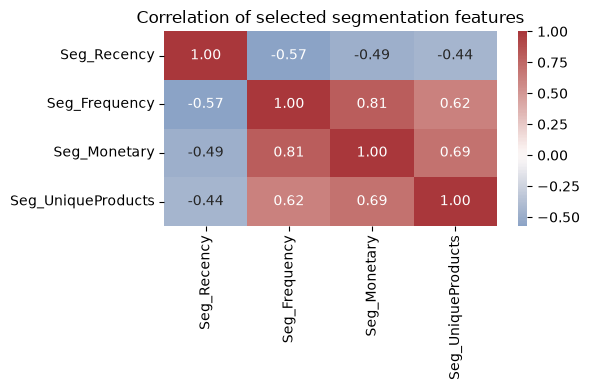

In [3]:
seg_features = ['Seg_Recency','Seg_Frequency','Seg_Monetary','Seg_UniqueProducts']
missing_seg = [c for c in seg_features if c not in customers.columns]
if missing_seg:
    raise ValueError(f'ویژگی‌های Segmentation موجود نیستند: {missing_seg}')
X_df = customers[seg_features].apply(pd.to_numeric, errors='coerce')
if X_df.isna().any().any() or not np.isfinite(X_df.to_numpy()).all():
    raise ValueError('ویژگی‌های Segmentation دارای NaN یا مقدار بی‌نهایت هستند.')
X = X_df.to_numpy(dtype=float)

corr = X_df.corr()
display(corr.round(3))
plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='vlag', center=0, fmt='.2f')
plt.title('Correlation of selected segmentation features')
plt.tight_layout(); plt.show()

## 4. مقایسه تعداد خوشه‌ها و الگوریتم‌ها

K-Means برای K=2 تا K=5 بررسی می‌شود. برای مقایسه منصفانه، Silhouette روی یک نمونه ثابت از مشتریان محاسبه می‌شود؛ Davies–Bouldin و Calinski–Harabasz روی برچسب‌های کل داده محاسبه می‌شوند. Ward روی کل داده و Gaussian Mixture نیز روی همان ویژگی‌های چهارگانه و K=2 تا K=4 مقایسه می‌شوند.

این معیارها معیارهای داخلی خوشه‌بندی‌اند؛ Accuracy نیستند و به‌تنهایی کیفیت تجاری را اثبات نمی‌کنند.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = np.sort(rng.choice(len(X), size=min(SIL_SAMPLE_SIZE, len(X)), replace=False))
rows = []

for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50, algorithm='lloyd')
    labels = km.fit_predict(X)
    sil = silhouette_score(X[sample_idx], labels[sample_idx])
    rows.append({'Algorithm':'KMeans','K':k,'Silhouette':sil,
                 'DaviesBouldin':davies_bouldin_score(X,labels),
                 'CalinskiHarabasz':calinski_harabasz_score(X,labels),
                 'MinCluster':int(np.bincount(labels).min()),
                 'MaxCluster':int(np.bincount(labels).max())})


for k in range(2,5):
    ward = AgglomerativeClustering(n_clusters=k, linkage='ward')
    lab = ward.fit_predict(X)
    rows.append({'Algorithm':'Ward_full','K':k,
                 'Silhouette':silhouette_score(X[sample_idx],lab[sample_idx]),
                 'DaviesBouldin':davies_bouldin_score(X,lab),
                 'CalinskiHarabasz':calinski_harabasz_score(X,lab),
                 'MinCluster':int(np.bincount(lab).min()),
                 'MaxCluster':int(np.bincount(lab).max())})

for k in range(2,5):
    gmm = GaussianMixture(n_components=k, random_state=RANDOM_STATE, n_init=5,
                          reg_covar=1e-5, covariance_type='full')
    lab = gmm.fit_predict(X)
    rows.append({'Algorithm':'GaussianMixture','K':k,
                 'Silhouette':silhouette_score(X[sample_idx],lab[sample_idx]),
                 'DaviesBouldin':davies_bouldin_score(X,lab),
                 'CalinskiHarabasz':calinski_harabasz_score(X,lab),
                 'MinCluster':int(np.bincount(lab).min()),
                 'MaxCluster':int(np.bincount(lab).max())})

model_comparison = pd.DataFrame(rows).sort_values(['Silhouette','DaviesBouldin'], ascending=[False,True]).reset_index(drop=True)
display(model_comparison.round(4))

,Algorithm,K,Silhouette,DaviesBouldin,CalinskiHarabasz,MinCluster,MaxCluster
0,KMeans,2,0.3957,0.9516,3902.8560,1752,2582
1,Ward_full,2,0.3851,0.9706,3663.7474,1635,2699
2,KMeans,3,0.2956,1.1384,3136.9417,890,1767
3,KMeans,4,0.2863,1.2028,2637.6332,818,1450
4,GaussianMixture,2,0.2730,1.1576,2107.8631,1505,2829
5,KMeans,5,0.2563,1.1732,2464.5936,493,1111
6,Ward_full,3,0.2379,1.3543,2500.3525,1033,1666
7,GaussianMixture,3,0.2113,1.4799,1683.2997,646,2187
8,Ward_full,4,0.2034,1.3840,2286.8189,523,1666
9,GaussianMixture,4,0.1297,2.1613,1344.2064,337,1669


### تحلیل حساسیت تعداد خوشه‌ها: K=2 در برابر K=3 و K=4

K=3 و K=4 علاوه بر معیارهای داخلی، از نظر اندازه خوشه‌ها و پروفایل رفتاری/اقتصادی بررسی می‌شوند. انتخاب K=2 به معنی ادعای وجود مرزهای طبیعی کاملاً جدا نیست؛ با Silhouette متوسط، آن را یک تفکیک مدیریتیِ درشت (فعال‌تر/کم‌فعال‌تر) می‌دانیم. Kهای بزرگ‌تر فقط در صورت ارزش عملیاتی بیشتر می‌توانند جایگزین شوند.

In [5]:
k_sensitivity_rows=[]
k_labels={}
for k in [2,3,4]:
    labels=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=50,algorithm='lloyd').fit_predict(X)
    k_labels[k]=labels
    sizes=pd.Series(labels).value_counts().sort_index()
    k_sensitivity_rows.append({'K':k,'Silhouette_sample':silhouette_score(X[sample_idx],labels[sample_idx]),
        'DaviesBouldin_full':davies_bouldin_score(X,labels),
        'CalinskiHarabasz_full':calinski_harabasz_score(X,labels),
        'Smallest_cluster':int(sizes.min()),'Largest_cluster':int(sizes.max()),
        'Smallest_cluster_pct':100*float(sizes.min())/len(X)})
k_sensitivity=pd.DataFrame(k_sensitivity_rows)
display(k_sensitivity.round(4))


k_profile_rows=[]
for k, labels in k_labels.items():
    tmp=customers[['Recency','Frequency','NetMonetary','UniqueProducts']].copy()
    tmp['Cluster']=labels
    prof=tmp.groupby('Cluster').agg(Customers=('Recency','size'),Median_Recency=('Recency','median'),
        Median_Frequency=('Frequency','median'),Median_NetMonetary=('NetMonetary','median'),
        Median_UniqueProducts=('UniqueProducts','median')).reset_index()
    prof.insert(0,'K',k)
    k_profile_rows.append(prof)
k_cluster_profiles=pd.concat(k_profile_rows,ignore_index=True)
display(k_cluster_profiles.round(2))

,K,Silhouette_sample,DaviesBouldin_full,CalinskiHarabasz_full,Smallest_cluster,Largest_cluster,Smallest_cluster_pct
0,2,0.3957,0.9516,3902.8560,1752,2582,40.4246
1,3,0.2956,1.1384,3136.9417,890,1767,20.5353
2,4,0.2863,1.2028,2637.6332,818,1450,18.8740


,K,Cluster,Customers,Median_Recency,Median_Frequency,Median_NetMonetary,Median_UniqueProducts
0,2,0,2582,99.0,1.0,338.83,20.0
1,2,1,1752,18.0,5.0,1891.83,88.0
2,3,0,1767,40.0,3.0,853.39,49.0
3,3,1,1677,158.0,1.0,245.94,13.0
4,3,2,890,11.0,9.0,3157.92,118.0
5,4,0,818,10.0,9.0,3279.58,119.0
6,4,1,1450,183.0,1.0,241.36,13.0
7,4,2,851,18.0,2.0,478.78,29.0
8,4,3,1215,67.0,3.0,1079.66,59.0


## 5. انتخاب مدل نهایی و آزمون پایداری

مدل نهایی بر اساس ترکیب معیارهای داخلی، اندازه معقول خوشه‌ها و قابلیت تفسیر انتخاب می‌شود. با توجه به ارزیابی قبلی پروژه، K-Means با چهار ویژگی و K=2 مدل مبناست؛ اگر جدول جدید شواهد روشن و پایدار علیه آن نشان دهد، انتخاب باید بازنگری شود.

پایداری با اجرای K-Means در چند مقدار seed و محاسبه Adjusted Rand Index (ARI) بین برچسب‌ها سنجیده می‌شود. ARI نزدیک ۱ یعنی تخصیص‌ها بین اجراها مشابه‌اند؛ این معیار نیز Accuracy نیست.

In [6]:
FINAL_K = 2
final_model = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=50, algorithm='lloyd')
final_labels = final_model.fit_predict(X)
customers['Cluster'] = final_labels

stability_rows=[]
reference_labels = final_labels
for seed in [7, 21, 42, 84, 123, 2026]:
    model = KMeans(n_clusters=FINAL_K, random_state=seed, n_init=50, algorithm='lloyd')
    labels = model.fit_predict(X)
    stability_rows.append({'Seed':seed,'ARI_vs_reference':adjusted_rand_score(reference_labels,labels),
                           'Inertia':float(model.inertia_)})
stability = pd.DataFrame(stability_rows)
print('Final model: KMeans, K=2, four prepared Seg_ features')
print('Sample silhouette:', round(silhouette_score(X[sample_idx], final_labels[sample_idx]),4))
print('Full-data Davies-Bouldin:', round(davies_bouldin_score(X,final_labels),4))
print('Full-data Calinski-Harabasz:', round(calinski_harabasz_score(X,final_labels),2))
display(stability.round(4))

Final model: KMeans, K=2, four prepared Seg_ features
Sample silhouette: 0.3957
Full-data Davies-Bouldin: 0.9516
Full-data Calinski-Harabasz: 3902.86


,Seed,ARI_vs_reference,Inertia
0,7,0.9899,9119.7941
1,21,0.9963,9119.6879
2,42,1.0000,9119.7339
3,84,0.9963,9119.6870
4,123,0.9972,9119.6954
5,2026,0.9991,9119.7188


## 6. تفسیر اقتصادی و رفتاری خوشه‌ها

برای هر خوشه تعداد مشتری، میانه و میانگین RFM، ارزش خالص و تنوع محصول محاسبه می‌شود. میانه برای داده‌های چوله معمولاً نماینده مقاوم‌تری است؛ میانگین نیز برای نشان‌دادن اثر مشتریان بسیار بزرگ گزارش می‌شود.

,Customers,Median_Recency,Median_Frequency,Median_Monetary,Median_NetMonetary,Median_AvgOrderValue,Median_UniqueProducts,Median_PurchasedInLast90Days,Mean_Recency,Mean_Frequency,Mean_Monetary,Mean_NetMonetary,Mean_UniqueProducts
Cluster,,,,,,,,,,,,,
0,2582,99.0,1.0,344.95,338.83,232.72,20.0,0.0,135.83,1.63,510.15,470.01,25.42
1,1752,18.0,5.0,1936.20,1891.83,346.50,88.0,1.0,30.45,8.10,4234.48,4038.22,114.46


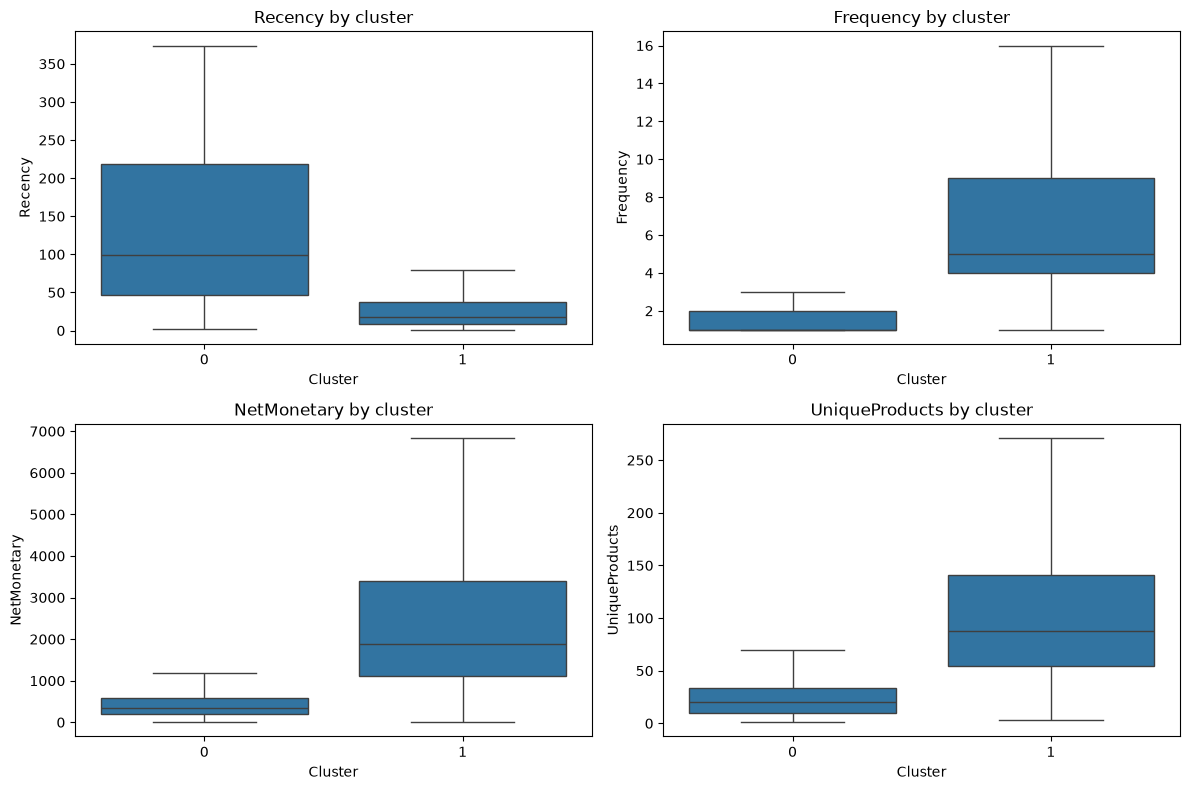

In [7]:
profile_cols = ['Recency','Frequency','Monetary','NetMonetary','AvgOrderValue','UniqueProducts','PurchasedInLast90Days']
cluster_profile = customers.groupby('Cluster').agg(
    Customers=('CustomerID','nunique'),
    **{f'Median_{c}':(c,'median') for c in profile_cols},
    **{f'Mean_{c}':(c,'mean') for c in ['Recency','Frequency','Monetary','NetMonetary','UniqueProducts']}
).round(2)
display(cluster_profile)

fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax, col in zip(axes.ravel(), ['Recency','Frequency','NetMonetary','UniqueProducts']):
    sns.boxplot(data=customers, x='Cluster', y=col, showfliers=False, ax=ax)
    ax.set_title(f'{col} by cluster')
plt.tight_layout(); plt.show()

## 6. اعتبارسنجی آماری و پایداری ساختار خوشه‌ها

در این بخش دو پرسش جدا بررسی می‌شود: (۱) آیا راه‌حل K-Means با تغییر نمونه آموزشی تقریباً حفظ می‌شود؟ (۲) آیا خوشه‌ها از نظر شاخص‌های اقتصادی/رفتاری تفاوت قابل‌توجهی دارند؟ مقدار p به‌تنهایی اهمیت عملی را نشان نمی‌دهد؛ بنابراین اندازه اثر Cliff's delta نیز گزارش می‌شود.


,Seed,Train_fraction,ARI_vs_full_solution,Inertia_on_subsample
0,11,0.8,0.9715,7412.1651
1,22,0.8,0.9770,7328.5719
2,33,0.8,0.9770,7250.2341
3,44,0.8,0.9798,7256.4113
4,55,0.8,0.9834,7236.9011
5,66,0.8,0.9843,7259.0373
6,77,0.8,0.9516,7266.9234
7,88,0.8,0.9734,7167.1602
8,99,0.8,0.9880,7344.5798
9,2026,0.8,0.9390,7086.5763


,Feature,Cluster0_median,Cluster1_median,Median_difference_1_minus_0,MannWhitney_U,p_value,Cliffs_delta_1_vs_0,p_value_bonferroni,Effect_magnitude
0,Recency,99.00,18.0000,-81.0000,3872256.0,0.0,-0.7120,0.0,Large
1,Frequency,1.00,5.0000,4.0000,196155.5,0.0,0.9133,0.0,Large
2,NetMonetary,338.83,1891.8300,1553.0000,224482.0,0.0,0.9008,0.0,Large
3,AvgOrderValue,232.72,346.4978,113.7778,1461426.5,0.0,0.3539,0.0,Medium
4,UniqueProducts,20.00,88.0000,68.0000,393047.0,0.0,0.8262,0.0,Large


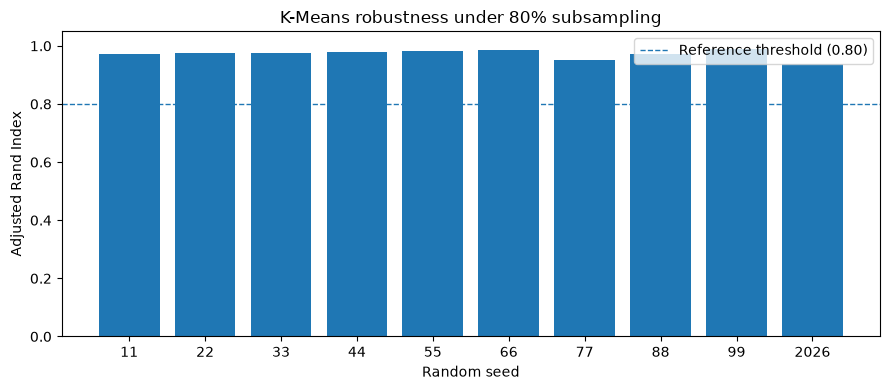

In [8]:
subsample_rows = []
subsample_n = max(FINAL_K + 1, int(0.80 * len(X)))
for seed in [11, 22, 33, 44, 55, 66, 77, 88, 99, 2026]:
    rng_sub = np.random.default_rng(seed)
    idx_sub = rng_sub.choice(len(X), size=subsample_n, replace=False)
    km_sub = KMeans(n_clusters=FINAL_K, random_state=seed, n_init=30, algorithm='lloyd')
    km_sub.fit(X[idx_sub])
    pred_all = km_sub.predict(X)
    subsample_rows.append({'Seed': seed, 'Train_fraction': subsample_n/len(X),
                           'ARI_vs_full_solution': adjusted_rand_score(final_labels, pred_all),
                           'Inertia_on_subsample': float(km_sub.inertia_)})
subsample_stability = pd.DataFrame(subsample_rows)
display(subsample_stability.round(4))

def cliffs_delta(a, b):
    a = pd.Series(a).dropna().to_numpy()
    b = pd.Series(b).dropna().to_numpy()
    if len(a) == 0 or len(b) == 0:
        return np.nan
    
    from scipy.stats import rankdata
    combined = np.concatenate([a, b])
    ranks = rankdata(combined, method='average')
    rank_sum_a = ranks[:len(a)].sum()
    u_a = rank_sum_a - len(a)*(len(a)+1)/2
    return float((2*u_a/(len(a)*len(b))) - 1)

stat_features = ['Recency','Frequency','NetMonetary','AvgOrderValue','UniqueProducts']
stat_rows = []
for feature in stat_features:
    g0 = customers.loc[customers['Cluster']==0, feature].dropna()
    g1 = customers.loc[customers['Cluster']==1, feature].dropna()
    if len(g0) and len(g1):
        test = mannwhitneyu(g0, g1, alternative='two-sided')
        stat_rows.append({'Feature':feature, 'Cluster0_median':g0.median(),
                          'Cluster1_median':g1.median(), 'Median_difference_1_minus_0':g1.median()-g0.median(),
                          'MannWhitney_U':float(test.statistic), 'p_value':float(test.pvalue),
                          'Cliffs_delta_1_vs_0':cliffs_delta(g1,g0)})
cluster_stats = pd.DataFrame(stat_rows)
if not cluster_stats.empty:
    
    cluster_stats['p_value_bonferroni'] = np.minimum(cluster_stats['p_value']*len(cluster_stats), 1.0)
    cluster_stats['Effect_magnitude'] = pd.cut(cluster_stats['Cliffs_delta_1_vs_0'].abs(),
        bins=[-0.001,0.147,0.33,0.474,1.001], labels=['Negligible','Small','Medium','Large'])
display(cluster_stats.round(4))

fig, ax = plt.subplots(figsize=(9,4))
plot_stab = subsample_stability.sort_values('Seed')
ax.bar(plot_stab['Seed'].astype(str), plot_stab['ARI_vs_full_solution'])
ax.axhline(0.8, linestyle='--', linewidth=1, label='Reference threshold (0.80)')
ax.set_ylim(0,1.05); ax.set_title('K-Means robustness under 80% subsampling')
ax.set_xlabel('Random seed'); ax.set_ylabel('Adjusted Rand Index'); ax.legend()
plt.tight_layout(); plt.show()


## 8. ارزش اقتصادی، فرصت بازاریابی و انتخاب ۵۰۰ مشتری

این امتیازها **شاخص رتبه‌بندی تصمیم‌یار** هستند، نه احتمال خرید و نه خروجی یک مدل supervised. وزن‌ها قاعده‌محور و قابل تغییرند؛ تحلیل حساسیت چند سناریوی وزن را با همبستگی رتبه و اشتراک Top-500 مقایسه می‌کند. برای جلوگیری از تمرکز 397 نفر در کمپین VIP loyalty، انتخاب نهایی از سقف 30٪ برای هر نوع کمپین استفاده می‌کند؛ این سقف یک سیاست عملیاتی شفاف است، نه پارامتر یادگرفته‌شده. برای جلوگیری از انتخاب مشتریانی با خرید کاملاً برگشتی، مشتریان دارای `NetMonetary > 0` اولویت دارند.

- EconomicScore: ارزش خالص، تکرار خرید و میانگین مبلغ سفارش.
- OpportunityScore: تازگی خرید، روند هزینه‌کرد (در صورت قابل تعریف بودن) و خرید در ۹۰ روز اخیر.
- برای `SpendGrowthIndex` گمشده، مقدار خنثی ۰.۵ در مقیاس نرمال‌شده استفاده می‌شود؛ مقدار گمشده به معنی رشد صفر فرض نشده است.

In [9]:

def percentile(s):
    return pd.to_numeric(s, errors='coerce').rank(pct=True).fillna(0)

def build_scores(frame, economic_weights=(0.45,0.35,0.20),
                 opportunity_weights=(0.45,0.30,0.25),
                 priority_weights=(0.50,0.35,0.15)):
    """شفاف و قاعده‌محور؛ خروجی احتمال خرید یا احتمال پاسخ نیست."""
    ew = np.asarray(economic_weights, dtype=float)
    ow = np.asarray(opportunity_weights, dtype=float)
    pw = np.asarray(priority_weights, dtype=float)
    ew, ow, pw = ew/ew.sum(), ow/ow.sum(), pw/pw.sum()

    net_rank = percentile(frame['NetMonetary'].clip(lower=0))
    freq_rank = percentile(frame['Frequency'])
    aov_rank = percentile(frame['AvgOrderValue'])
    economic = (ew[0]*net_rank + ew[1]*freq_rank + ew[2]*aov_rank)*100

    growth = pd.to_numeric(frame['SpendGrowthIndex'], errors='coerce')
    growth = growth.replace([np.inf,-np.inf],np.nan).clip(-1,1)
    growth_norm = ((growth+1)/2).fillna(0.5)
    recent_flag = frame['PurchasedInLast90Days'].astype('boolean').fillna(False).astype(int)
    recency_rank = percentile(-frame['Recency'])
    opportunity = (ow[0]*recency_rank + ow[1]*growth_norm + ow[2]*recent_flag)*100
    priority = (pw[0]*economic + pw[1]*opportunity + pw[2]*recency_rank*100)
    return economic, opportunity, priority, recency_rank*100

customers['EconomicScore'], customers['OpportunityScore'], customers['PriorityScore'], customers['RecencyScore'] = build_scores(customers)


def campaign_rule(r):
    if r['EconomicScore'] >= 80 and r['Recency'] <= 30:
        return 'VIP loyalty / early access'
    if r['EconomicScore'] >= 80:
        return 'VIP win-back / personal offer'
    if r['Recency'] <= 30 and r['Frequency'] >= 2:
        return 'Cross-sell / bundle'
    if r['Recency'] > 90:
        return 'Reactivation offer'
    return 'Personalized recommendation'

positive_pool = customers.loc[customers['NetMonetary'] > 0].copy()
target_pool = positive_pool if len(positive_pool) >= 500 else customers.copy()
target_pool['Campaign'] = target_pool.apply(campaign_rule, axis=1)

TARGET_N = min(500, len(target_pool))
MAX_CAMPAIGN_SHARE = 0.30
CAMPAIGN_CAP = int(np.ceil(TARGET_N * MAX_CAMPAIGN_SHARE))
ranked_pool = target_pool.sort_values(['PriorityScore','EconomicScore'], ascending=False)
chosen_indices, campaign_counts = [], {}
for idx, row in ranked_pool.iterrows():
    campaign = row['Campaign']
    if campaign_counts.get(campaign, 0) < CAMPAIGN_CAP:
        chosen_indices.append(idx)
        campaign_counts[campaign] = campaign_counts.get(campaign, 0) + 1
    if len(chosen_indices) == TARGET_N:
        break
top500 = target_pool.loc[chosen_indices].copy()
top500 = top500.sort_values(['PriorityScore','EconomicScore'], ascending=False).head(TARGET_N)

print('Eligible positive-net customers:', len(positive_pool))
print('Selected customers:',len(top500),'| unique IDs:',top500['CustomerID'].nunique())
print('Per-campaign cap:',CAMPAIGN_CAP)
display(top500['Campaign'].value_counts().rename_axis('Campaign').to_frame('Customers'))
display(top500[['CustomerID','Cluster','EconomicScore','OpportunityScore','PriorityScore','Campaign']].head(10))

weight_scenarios = {
    'Baseline': ((0.45,0.35,0.20),(0.45,0.30,0.25),(0.50,0.35,0.15)),
    'Economic_heavier': ((0.55,0.30,0.15),(0.40,0.35,0.25),(0.60,0.25,0.15)),
    'Opportunity_heavier': ((0.40,0.35,0.25),(0.55,0.30,0.15),(0.40,0.45,0.15)),
    'Recency_heavier': ((0.45,0.35,0.20),(0.55,0.25,0.20),(0.40,0.30,0.30)),
    'Balanced': ((1/3,1/3,1/3),(1/3,1/3,1/3),(1/3,1/3,1/3))
}
base_rank = customers['PriorityScore'].rank(ascending=False, method='min')
base_top_ids = set(customers.loc[base_rank <= 500, 'CustomerID'])
sensitivity_rows=[]
for name, (ew,ow,pw) in weight_scenarios.items():
    e_s,o_s,p_s,_ = build_scores(customers, ew,ow,pw)
    rank_s = p_s.rank(ascending=False, method='min')
    top_ids = set(customers.loc[rank_s <= 500, 'CustomerID'])
    sensitivity_rows.append({
        'Scenario':name,
        'Spearman_vs_baseline':float(spearmanr(base_rank,rank_s).statistic),
        'Top500_overlap_count':len(base_top_ids & top_ids),
        'Top500_overlap_pct':100*len(base_top_ids & top_ids)/max(1,len(base_top_ids)),
        'Economic_weights':str(tuple(round(x,3) for x in ew)),
        'Opportunity_weights':str(tuple(round(x,3) for x in ow)),
        'Priority_weights':str(tuple(round(x,3) for x in pw))
    })
score_sensitivity = pd.DataFrame(sensitivity_rows)
display(score_sensitivity.round(3))


Eligible positive-net customers: 4325
Selected customers: 500 | unique IDs: 500
Per-campaign cap: 150


,Customers
Campaign,
VIP loyalty / early access,150
Cross-sell / bundle,150
VIP win-back / personal offer,116
Personalized recommendation,84


,CustomerID,Cluster,EconomicScore,OpportunityScore,PriorityScore,Campaign
1058,13777,1,97.998962,97.763580,98.157897,VIP loyalty / early access
2836,16210,1,97.952238,97.232255,97.709762,VIP loyalty / early access
3680,17389,1,98.540032,94.907159,97.428685,VIP loyalty / early access
4197,18102,1,99.867328,92.065764,97.097844,VIP loyalty / early access
2461,15694,1,92.833410,97.200376,95.378000,VIP loyalty / early access
1689,14646,1,99.865021,87.707269,95.332408,VIP loyalty / early access
1983,15061,1,99.118597,90.329821,95.228151,VIP loyalty / early access
2063,15159,1,96.987771,91.484852,95.215937,VIP loyalty / early access
570,13098,1,98.546954,88.560423,94.971979,VIP loyalty / early access
3174,16684,1,99.387979,89.829216,94.862295,VIP loyalty / early access


,Scenario,Spearman_vs_baseline,Top500_overlap_count,Top500_overlap_pct,Economic_weights,Opportunity_weights,Priority_weights
0,Baseline,1.000,500,100.0,"(0.45, 0.35, 0.2)","(0.45, 0.3, 0.25)","(0.5, 0.35, 0.15)"
1,Economic_heavier,0.991,469,93.8,"(0.55, 0.3, 0.15)","(0.4, 0.35, 0.25)","(0.6, 0.25, 0.15)"
2,Opportunity_heavier,0.994,460,92.0,"(0.4, 0.35, 0.25)","(0.55, 0.3, 0.15)","(0.4, 0.45, 0.15)"
3,Recency_heavier,0.991,448,89.6,"(0.45, 0.35, 0.2)","(0.55, 0.25, 0.2)","(0.4, 0.3, 0.3)"
4,Balanced,0.983,442,88.4,"(0.333, 0.333, 0.333)","(0.333, 0.333, 0.333)","(0.333, 0.333, 0.333)"


## 9. اعتبارسنجی تجاری فهرست ۵۰۰ مشتری منتخب

برای ارزیابی کاربردپذیری فهرست، مشتریان Top-500 با سایر مشتریان مقایسه می‌شوند. معیارهای اصلی شامل میانه ارزش خالص، دفعات خرید، امتیاز اقتصادی و فرصت بازاریابی است. این مقایسه نشان می‌دهد منطق رتبه‌بندی چه گروهی را انتخاب کرده؛ اما به‌تنهایی اثبات نمی‌کند که کمپین باعث افزایش فروش خواهد شد.


,Metric,Top500_count,Other_count,Top500_median,Other_median,Median_lift_pct,Top500_mean,Other_mean
0,NetMonetary,500,3834,2755.26,546.02,404.61,7905.08,1130.93
1,Frequency,500,3834,7.00,2.00,250.00,11.87,3.25
2,Recency,500,3834,9.00,61.00,-85.25,21.85,102.54
3,EconomicScore,500,3834,81.14,45.20,79.49,82.68,45.75
4,OpportunityScore,500,3834,83.11,61.82,34.43,81.20,52.33
5,PriorityScore,500,3834,80.85,48.19,67.76,81.22,48.18


,Cluster,Customers,Median_NetMonetary,Mean_NetMonetary,Median_OpportunityScore
0,0,6,2855.19,2791.40,68.27
1,1,494,2755.26,7967.19,83.11


,Campaign,Customers,Median_PriorityScore,Median_NetMonetary
0,Cross-sell / bundle,150,81.74,1921.03
1,Personalized recommendation,84,70.80,1920.11
2,VIP loyalty / early access,150,90.91,8528.73
3,VIP win-back / personal offer,116,74.45,3527.06


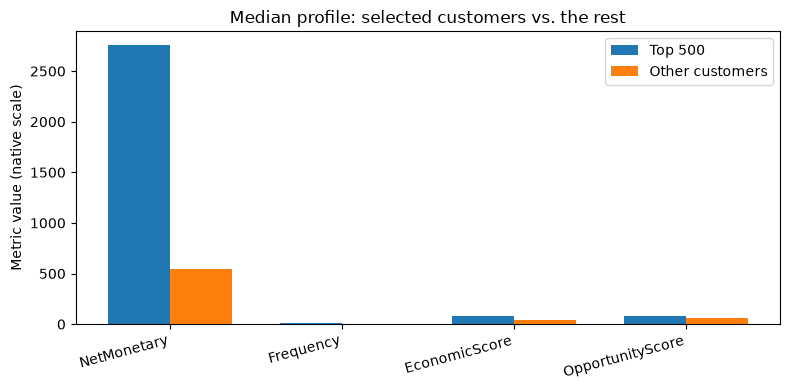

In [10]:
top_ids = set(top500['CustomerID'])
customers['IsTop500'] = customers['CustomerID'].isin(top_ids)
comparison_metrics = ['NetMonetary','Frequency','Recency','EconomicScore','OpportunityScore','PriorityScore']
commercial_rows = []
for metric in comparison_metrics:
    selected = customers.loc[customers['IsTop500'], metric].dropna()
    other = customers.loc[~customers['IsTop500'], metric].dropna()
    commercial_rows.append({'Metric':metric, 'Top500_count':len(selected), 'Other_count':len(other),
        'Top500_median':selected.median(), 'Other_median':other.median(),
        'Median_lift_pct':(selected.median()/other.median()-1)*100 if other.median()!=0 else np.nan,
        'Top500_mean':selected.mean(), 'Other_mean':other.mean()})
top500_validation = pd.DataFrame(commercial_rows)
display(top500_validation.round(2))

top500_cluster_mix = top500.groupby('Cluster').agg(Customers=('CustomerID','nunique'),
    Median_NetMonetary=('NetMonetary','median'), Mean_NetMonetary=('NetMonetary','mean'),
    Median_OpportunityScore=('OpportunityScore','median')).reset_index()
top500_campaign_mix = top500.groupby('Campaign').agg(Customers=('CustomerID','nunique'),
    Median_PriorityScore=('PriorityScore','median'), Median_NetMonetary=('NetMonetary','median')).reset_index()
display(top500_cluster_mix.round(2)); display(top500_campaign_mix.round(2))

fig, ax = plt.subplots(figsize=(8,4))
plot_df = top500_validation[top500_validation['Metric'].isin(['NetMonetary','Frequency','EconomicScore','OpportunityScore'])]
x = np.arange(len(plot_df)); w = 0.36
ax.bar(x-w/2, plot_df['Top500_median'], w, label='Top 500')
ax.bar(x+w/2, plot_df['Other_median'], w, label='Other customers')
ax.set_xticks(x); ax.set_xticklabels(plot_df['Metric'], rotation=15, ha='right')
ax.set_title('Median profile: selected customers vs. the rest')
ax.set_ylabel('Metric value (native scale)'); ax.legend()
plt.tight_layout(); plt.show()


## 10. Association Rule Mining — قوانین دقیق دو‌محصولی

ماتریس ورودی ۰/۱ است. برای کنترل زمان و حافظه، ابتدا محصولاتی با Support حداقل ۰.۵٪ نگه داشته و سپس حداکثر ۱۵۰ محصول پرتکرارتر بررسی می‌شوند. برای تمام زوج‌های این مجموعه، هم‌رخدادی دقیق محاسبه می‌شود و قواعد جهت‌دار با آستانه‌های Support≥0.5%، Confidence≥30% و Lift≥1.10 گزارش می‌شوند.

**محدودیت روش:** این محاسبه دقیق قوانین دوآیتمی است؛ FP-Growth یا Apriori کامل برای مجموعه‌های چندآیتمی نیست. بنابراین در گزارش آن را صریحاً «استخراج قوانین دو‌محصولی مبتنی بر هم‌رخدادی» بنویسید.

In [11]:
product_cols = [c for c in baskets.columns if c != 'InvoiceNo']
B_all = baskets[product_cols].fillna(0).to_numpy(dtype=np.uint8)
if not np.isin(B_all,[0,1]).all():
    raise ValueError('ستون‌های محصول باید فقط 0 و 1 داشته باشند.')
n_invoices = len(B_all)
support_all = B_all.mean(axis=0)
eligible = np.where(support_all >= MIN_ITEM_SUPPORT)[0]
if len(eligible) > MAX_ARM_ITEMS:
    eligible = eligible[np.argsort(support_all[eligible])[::-1][:MAX_ARM_ITEMS]]
selected_products = [product_cols[i] for i in eligible]
B = B_all[:,eligible]
item_support = B.mean(axis=0)
co_support = (B.T @ B) / n_invoices
rule_rows=[]
for i, a in enumerate(selected_products):
    for j, c in enumerate(selected_products):
        if i == j: continue
        supp = float(co_support[i,j])
        conf = supp / item_support[i] if item_support[i] else 0.0
        lift = conf / item_support[j] if item_support[j] else 0.0
        if supp >= MIN_ITEM_SUPPORT and conf >= MIN_CONFIDENCE and lift >= MIN_LIFT:
            rule_rows.append({'antecedent':str(a),'consequent':str(c),'support':supp,
                              'confidence':conf,'consequent_support':float(item_support[j]),'lift':lift})
association_rules = pd.DataFrame(rule_rows,columns=['antecedent','consequent','support','confidence','consequent_support','lift'])
if not association_rules.empty:
    association_rules = association_rules.sort_values(['lift','confidence','support'],ascending=False).reset_index(drop=True)
print(f'Invoices: {n_invoices:,} | Products evaluated: {len(selected_products)} | Rules: {len(association_rules):,}')
display(association_rules.head(20))

Invoices: 18,267 | Products evaluated: 150 | Rules: 142


,antecedent,consequent,support,confidence,consequent_support,lift
0,22553,22557,0.010784,0.351786,0.030985,11.353480
1,22557,22553,0.010784,0.348057,0.030656,11.353480
2,21975,84992,0.012317,0.375000,0.033667,11.138415
3,84992,21975,0.012317,0.365854,0.032846,11.138415
4,22553,22554,0.012755,0.416071,0.038539,10.795990
5,22554,22553,0.012755,0.330966,0.030656,10.795990
6,22554,22557,0.012865,0.333807,0.030985,10.773232
7,22557,22554,0.012865,0.415194,0.038539,10.773232
8,23204,22356,0.013631,0.427101,0.040620,10.514633
9,22356,23204,0.013631,0.335580,0.031915,10.514633


## 11. اعتبارسنجی خروجی‌ها و ذخیره نتایج

کنترل‌های نهایی قبل از ذخیره انجام می‌شوند. خروجی‌ها شامل برچسب خوشه هر مشتری، پروفایل خوشه‌ها، مقایسه الگوریتم‌ها، پایداری، فهرست ۵۰۰ نفر، قوانین انجمنی و خلاصه معیارها هستند.

In [12]:
OUTPUT_DIR = customer_path.parent.parent / 'modeling_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

checks=[]
def add_check(name, ok, detail=''):
    checks.append({'Check':name,'Status':'PASS' if bool(ok) else 'FAIL','Detail':str(detail)})

add_check('CustomerID unique',customers['CustomerID'].is_unique)
add_check('One cluster label per customer',customers['Cluster'].notna().all())
add_check('Exactly two non-empty clusters',customers['Cluster'].nunique()==2,customers['Cluster'].value_counts().to_dict())
add_check('K sensitivity includes K=2,3,4',set(k_sensitivity['K'])=={2,3,4})
add_check('Ward comparison fitted on full dataset',all(model_comparison.loc[model_comparison['Algorithm']=='Ward_full','K'].isin([2,3,4])))
add_check('Top500 has 500 rows',len(top500)==500,len(top500))
add_check('Top500 IDs unique',top500['CustomerID'].is_unique)
add_check('Campaign share cap respected',top500['Campaign'].value_counts().max() <= CAMPAIGN_CAP,top500['Campaign'].value_counts().to_dict())
add_check('Score sensitivity scenarios present',len(score_sensitivity)>=4)
add_check('Top500 net value positive where feasible', (top500['NetMonetary']>0).all() if len(positive_pool)>=500 else True)
add_check('Basket binary',np.isin(B_all,[0,1]).all())
add_check('Basket invoice unique',baskets['InvoiceNo'].is_unique)
add_check('Subsample stability calculated for 10 seeds',len(subsample_stability)==10)
add_check('Cluster statistical comparison covers five features',len(cluster_stats)==5)
add_check('Top500 commercial comparison covers six metrics',len(top500_validation)==6)
add_check('Top500 customer IDs are subset of customer table',set(top500['CustomerID']).issubset(set(customers['CustomerID'])))
validation = pd.DataFrame(checks)
display(validation)
if (validation['Status']=='FAIL').any():
    raise AssertionError('حداقل یک کنترل نهایی شکست خورده است؛ خروجی نهایی ذخیره نشد.')

customers.to_csv(OUTPUT_DIR/'customer_segments_and_scores.csv',index=False)
cluster_profile.to_csv(OUTPUT_DIR/'customer_segment_profile.csv')
model_comparison.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False)
k_sensitivity.to_csv(OUTPUT_DIR/'k_sensitivity.csv',index=False)
k_cluster_profiles.to_csv(OUTPUT_DIR/'k_cluster_profiles.csv',index=False)
score_sensitivity.to_csv(OUTPUT_DIR/'score_weight_sensitivity.csv',index=False)
top500['Campaign'].value_counts().rename_axis('Campaign').to_frame('Customers').to_csv(OUTPUT_DIR/'campaign_mix_top500.csv')
stability.to_csv(OUTPUT_DIR/'kmeans_stability.csv',index=False)
subsample_stability.to_csv(OUTPUT_DIR/'kmeans_subsample_stability.csv',index=False)
cluster_stats.to_csv(OUTPUT_DIR/'cluster_statistical_tests.csv',index=False)
top500_validation.to_csv(OUTPUT_DIR/'top500_commercial_validation.csv',index=False)
top500_cluster_mix.to_csv(OUTPUT_DIR/'top500_cluster_mix.csv',index=False)
top500_campaign_mix.to_csv(OUTPUT_DIR/'top500_campaign_mix.csv',index=False)
top500.to_csv(OUTPUT_DIR/'top500_customers.csv',index=False)
association_rules.to_csv(OUTPUT_DIR/'association_rules_2item.csv',index=False)
validation.to_csv(OUTPUT_DIR/'modeling_validation.csv',index=False)

metrics={
 'n_customers':int(len(customers)), 'n_invoices':int(len(baskets)),
 'n_products_in_basket':int(len(product_cols)), 'selected_algorithm':'KMeans', 'selected_k':2,
 'selected_features':seg_features,
 'k_sensitivity':k_sensitivity.to_dict(orient='records'),
 'ward_fit_scope':'full_dataset',
 'campaign_cap_share':MAX_CAMPAIGN_SHARE,
 'campaign_mix':{str(k):int(v) for k,v in top500['Campaign'].value_counts().items()},
 'score_weight_sensitivity':score_sensitivity.to_dict(orient='records'),
 'silhouette_sampled':float(silhouette_score(X[sample_idx],final_labels[sample_idx])),
 'davies_bouldin_full':float(davies_bouldin_score(X,final_labels)),
 'calinski_harabasz_full':float(calinski_harabasz_score(X,final_labels)),
 'cluster_sizes':{str(k):int(v) for k,v in customers['Cluster'].value_counts().sort_index().items()},
 'mean_stability_ARI':float(stability['ARI_vs_reference'].mean()),
 'mean_subsample_stability_ARI':float(subsample_stability['ARI_vs_full_solution'].mean()),
 'min_subsample_stability_ARI':float(subsample_stability['ARI_vs_full_solution'].min()),
 'cluster_statistically_tested_features':stat_features,
 'top500_median_net_monetary':float(top500['NetMonetary'].median()),
 'other_customers_median_net_monetary':float(customers.loc[~customers['IsTop500'],'NetMonetary'].median()),
 'top500_count':int(len(top500)), 'association_rule_count':int(len(association_rules)),
 'association_method':'exact pairwise co-occurrence; not FP-Growth or full Apriori',
 'validation_passed':int((validation['Status']=='PASS').sum()),
 'validation_failed':int((validation['Status']=='FAIL').sum())
}
with open(OUTPUT_DIR/'modeling_metrics.json','w',encoding='utf-8') as f:
    json.dump(metrics,f,ensure_ascii=False,indent=2)
print(json.dumps(metrics,ensure_ascii=False,indent=2))
print('All outputs saved to:',OUTPUT_DIR.resolve())

,Check,Status,Detail
0,CustomerID unique,PASS,
1,One cluster label per customer,PASS,
2,Exactly two non-empty clusters,PASS,"{0: 2582, 1: 1752}"
3,"K sensitivity includes K=2,3,4",PASS,
4,Ward comparison fitted on full dataset,PASS,
5,Top500 has 500 rows,PASS,500
6,Top500 IDs unique,PASS,
7,Campaign share cap respected,PASS,"{'VIP loyalty / early access': 150, 'Cross-sel..."
8,Score sensitivity scenarios present,PASS,
9,Top500 net value positive where feasible,PASS,


{
  "n_customers": 4334,
  "n_invoices": 18267,
  "n_products_in_basket": 1612,
  "selected_algorithm": "KMeans",
  "selected_k": 2,
  "selected_features": [
    "Seg_Recency",
    "Seg_Frequency",
    "Seg_Monetary",
    "Seg_UniqueProducts"
  ],
  "k_sensitivity": [
    {
      "K": 2,
      "Silhouette_sample": 0.3956567049023487,
      "DaviesBouldin_full": 0.9516318108379871,
      "CalinskiHarabasz_full": 3902.8560059110005,
      "Smallest_cluster": 1752,
      "Largest_cluster": 2582,
      "Smallest_cluster_pct": 40.42455006922012
    },
    {
      "K": 3,
      "Silhouette_sample": 0.2956375800084941,
      "DaviesBouldin_full": 1.1384389311081156,
      "CalinskiHarabasz_full": 3136.941716935164,
      "Smallest_cluster": 890,
      "Largest_cluster": 1767,
      "Smallest_cluster_pct": 20.535302261190587
    },
    {
      "K": 4,
      "Silhouette_sample": 0.286299643609946,
      "DaviesBouldin_full": 1.2028342992137684,
      "CalinskiHarabasz_full": 2637.6332185894116,

## 12. جمع‌بندی علمی و محدودیت‌ها

- مسئله Customer Segmentation بدون برچسب واقعی است؛ Accuracy طبقه‌بندی تعریف نمی‌شود.
- Silhouette، Davies–Bouldin و Calinski–Harabasz معیارهای داخلی‌اند و باید همراه با پروفایل اقتصادی و پایداری تفسیر شوند.
- EconomicScore، OpportunityScore و PriorityScore شاخص‌های قاعده‌محور تصمیم‌یارند، نه احتمال خرید یا پاسخ. تحلیل حساسیت وزن‌ها میزان ثبات رتبه و اشتراک Top-500 را گزارش می‌کند؛ این تحلیل جایگزین اعتبارسنجی با داده پاسخ واقعی کمپین نیست.
- انتخاب ۵۰۰ مشتری یک فهرست هدف‌گذاری مبتنی بر امتیاز و سقف سهم 30٪ برای هر کمپین است تا فهرست به یک کمپین (مانند VIP loyalty) محدود نشود. سقف تنوع، سیاست تجاری قابل تنظیم است و باید با ظرفیت و اهداف واقعی بازاریابی تطبیق داده شود. اثربخشی فقط با آزمایش کنترل‌شده سنجیده می‌شود.
- بخش ARM فقط قوانین دو‌محصولی را در حداکثر ۱۵۰ محصول پرتکرار استخراج می‌کند؛ این روش اجرای کامل FP-Growth/Apriori نیست و itemsetهای سه‌محصولی یا بیشتر را پوشش نمی‌دهد.
- Silhouette حدود 0.40 نشان‌دهنده جداسازی متوسط است؛ K=2 از نظر معیارهای داخلی بهتر است، اما K=3/4 در جدول حساسیت و پروفایل‌های تجاری مستند شده‌اند و می‌توانند برای کمپین‌های تخصصی‌تر مفید باشند.
- Ward در این نسخه روی کل داده fit شده است؛ بنابراین مقایسه آن با K-Means دیگر مبتنی بر اندازه نمونه متفاوت نیست.
- اعتبارسنجی زمانی با دو فایل تجمیعی فعلی ممکن نیست، چون تاریخچه تراکنش سطح مشتری و برچسب زمانی train/test در این ورودی‌ها موجود نیست. برای آن باید داده تراکنش خام دارای InvoiceDate و CustomerID در چند بازه زمانی در دسترس باشد.
- نبود برچسب واقعی یعنی Accuracy طبقه‌بندی معیار مناسبی نیست؛ معیارهای داخلی و پایداری گزارش شده‌اند.
- خوشه‌بندی مشتریان به معنی پیش‌بینی Churn نیست.

**متن پیشنهادی گزارش:** «با توجه به نبود برچسب مرجع برای مشتریان، عملکرد خوشه‌بندی با معیارهای داخلی ارزیابی شد. K-Means با دو خوشه و چهار ویژگی استانداردشده به‌عنوان مدل مبنا انتخاب شد. کیفیت آن با Silhouette، Davies–Bouldin، Calinski–Harabasz، پایداری برچسب‌ها و قابلیت تفسیر تجاری بررسی شد. امتیازهای اقتصادی و فرصت بازاریابی صرفاً برای رتبه‌بندی مشتریان و انتخاب گروه هدف کمپین استفاده شدند و به‌عنوان مدل پیش‌بینی تفسیر نمی‌شوند.»

**توجیه انتخاب K=2 برای گزارش:** «در مقایسه K=2، K=3 و K=4، K=2 بالاترین Silhouette و Calinski–Harabasz و کمترین Davies–Bouldin را روی همین ویژگی‌ها نشان داد. هرچند Silhouette نزدیک 0.40 جداسازی متوسط را نشان می‌دهد، K=2 به‌عنوان تقسیم‌بندی مدیریتی ساده و پایدار انتخاب شد؛ Kهای بالاتر سگمنت‌های کوچک‌تر و تخصصی‌تر می‌سازند، اما در این داده با افت معیارهای داخلی همراه‌اند.»

- **اعتبارسنجی افزوده:** ARI زیرنمونه‌گیری، اندازه اثر Cliff، آزمون Mann–Whitney با اصلاح Bonferroni و مقایسه Top-500 با سایر مشتریان در خروجی‌ها ذخیره می‌شوند. معنی‌داری آماری معادل اثبات اثربخشی کمپین نیست؛ برای آن باید آزمایش A/B یا گروه کنترل اجرا شود.
- **محدودیت ARM:** دامنه این نسخه همچنان قوانین دقیق دو‌محصولی در میان حداکثر ۱۵۰ محصول پرتکرار است؛ این روش را نباید Apriori یا FP-Growth کامل معرفی کرد.